# What comes after five songs?
### Spotify playlist continuation with track history, artist identity, and audio similarity

Given five consecutive tracks in a curated playlist, rank the catalogue for the track
in the sixth position. The central experiment measures the change in retrieval quality
when a model that already knows playlist history and artist identity gains access to
audio descriptors.

**Reading the notebook.** Sections 1-5 follow the assignment rubric: task, data,
modeling, evaluation, and related work with findings. Every reported result is produced
by the displayed code. The experiment is executed in Section 4; the result and its
interpretation appear there and in Section 5. This version does not export HTML.

To rerun, put `songs620.csv` beside the notebook, keep it in `data/`, or set
`SONGS620_PATH` to its location. A Desktop copy is also recognized. Run from the
folder containing the notebook. Install `requirements.txt` if needed.

[1 · Task](#part-1) · [2 · Data](#part-2) · [3 · Models](#part-3) ·
[4 · Evaluation](#part-4) · [5 · Findings and related work](#part-5)

<a id="part-1"></a>
## 1 · Predictive task and validity criteria

**Observation and target.** Each test playlist supplies one opening query. Positions
0-4 are visible; position 5 supplies the single observed target. A playlist curator's
ordering supplies the label. Playback, skips, user satisfaction, and other plausible
continuations are unobserved. This experiment predicts the **immediate next track**,
rather than recovering arbitrary missing playlist members.

**Prediction setting.** A recommender can look up track IDs, artist IDs, and static
audio features for the entire snapshot catalogue, including newly encountered songs.
Playlist membership, track popularity, and transitions come only from training
playlists. This is a **known-catalogue, new-playlist** experiment. Treating every song
in the file as available at once is an explicit assumption because release and
playlist creation times are unavailable. Previously played tracks remain eligible
because curators can repeat them. A playlist is the context; no listener identities
are supplied, so this is not individual-user preference prediction.

**Primary comparison.** Compare the same logistic ranking pipeline with and without
audio, with artist features in both. The primary endpoint is **Hit Rate@10**, the
fraction of opening queries with the exact target in the top ten. **MRR@10** averages
reciprocal target rank for top-ten hits and zero otherwise. The target's median rank
shows movement below the cutoff. The full catalogue competes on every query.

**Baselines.** Uniform random ranking in expectation, training popularity, a last-artist
rule, item-item cosine similarity, a first-order Markov model, and audio similarity.
Three learned feature configurations separately measure history, artist, and audio.

**Validation plan.** Split playlist IDs 80/10/10 **before** constructing windows.
Choose inverse regularization strength C on validation openings. Freeze the fitted
models and evaluate test openings once for the primary comparison. No validation
playlists are folded into the final training statistics. Report results by zero versus
positive training support, a paired playlist-bootstrap interval for the primary
difference, and sensitivity checks for prefix order and position. Seed 42 is fixed;
its catalogue coverage was discussed during planning, so the split was not selected
blind to coverage. Model performance is not used to select or change it.

**Validity criteria.** Better than popularity is useful, but the central claim requires
an incremental gain from audio over history plus artist. A positive point estimate
with an interval spanning zero is insufficient evidence of a reliable gain. Better
median rank alone does not establish a benefit when only ten songs are shown.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import platform
from pathlib import Path
from time import perf_counter
import warnings

ROOT = Path.cwd()
OUT = ROOT / "output" / "next_song"
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "tmp" / "matplotlib"))
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.sparse import csr_matrix, issparse
from scipy.stats import binomtest
import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, normalize
from threadpoolctl import threadpool_limits

SEED = 42
HISTORY_LENGTH = 5
NEGATIVES = 10
REGULARIZATION = [0.01, 0.1, 1.0, 10.0]
AUDIO_COLUMNS = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                 "instrumentalness", "liveness", "valence", "tempo", "duration_ms"]
HISTORY_NAMES = ["log_track_support", "cosine_mean", "cosine_max", "cosine_last",
                 "log_markov_last", "log_markov_mean", "repeat_fraction"]
ARTIST_NAMES = ["same_last_artist", "history_artist_fraction", "log_artist_support",
                "log_artist_markov_last", "log_artist_markov_mean"]
AUDIO_NAMES = ["audio_cosine_last", "audio_cosine_centroid", "audio_distance_last",
               "audio_distance_centroid"] + ["audio_last_abs_"+c for c in AUDIO_COLUMNS]
FEATURE_NAMES = HISTORY_NAMES + ARTIST_NAMES + AUDIO_NAMES
MODEL_FEATURES = {
    "History": list(range(len(HISTORY_NAMES))),
    "History + artist": list(range(len(HISTORY_NAMES)+len(ARTIST_NAMES))),
    "History + artist + audio": list(range(len(FEATURE_NAMES))),
}
BASELINES = ["Popularity", "Last artist", "Item cosine", "Markov", "Audio similarity"]



from IPython.display import display, Image, Markdown
_thread_limit = threadpool_limits(limits=4)

<a id="part-2"></a>
## 2 · Data, collection context, exploration, and preprocessing

### 2.1 What is known about this file

The supplied CSV links Spotify track URIs to playlist IDs (`pid`) and track positions
(`pos`), with artist/album metadata and audio descriptors. Its schema and playlist IDs
0-999 are consistent with an audio-enriched subset of the Million Playlist Dataset
(MPD), but **the exact derivation is unverified**: no collection script, source manifest,
sampling history, or enrichment date is supplied. The filename does not imply that
the file contains 620 tracks. No URL columns are fetched in this experiment.

Spotify's original MPD was released for playlist-continuation research and contains
one million playlists and over two million tracks [R1]. That describes the parent
resource, not the size or authenticated provenance of this local file. Curator order
is a useful label but is not evidence of actual listening behavior. No dates permit
chronological splitting or a check that all candidates existed at query time.

### 2.2 Preserve the sequence, separate the playlists

The loader checks nonmissing identifiers, integer positions, no duplicate `(pid,pos)`
pairs, contiguous positions from zero, and consistent per-track modeled metadata.
It sorts by playlist and position. Repeated `(pid,track)` memberships **remain in
the sequence**; binary co-occurrence statistics separately count each track once per
training playlist. This separates real repeat events from double-counting popularity.

The seed-42 permutation of sorted playlist IDs assigns the first 800 to training,
the next 100 to validation, and the last 100 to test. Every length-six training window
produces five inputs and one immediate-successor label. Validation and primary test
use only the opening window per eligible playlist. A playlist with only five tracks
has no sixth label and is reported as ineligible, rather than moved to another split.

In [2]:
def find_dataset():
    override = os.environ.get("SONGS620_PATH")
    if override:
        path = Path(override).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f"SONGS620_PATH does not exist: {path}")
        return path.resolve()
    for path in [ROOT / "songs620.csv", ROOT / "data" / "songs620.csv",
                 Path.home() / "Desktop" / "songs620.csv"]:
        if path.is_file():
            return path.resolve()
    raise FileNotFoundError("Put songs620.csv beside the notebook or set SONGS620_PATH.")


def queries_from_sequences(sequences, pids, start=0, all_windows=False):
    rows = []
    for pid in pids:
        seq = sequences[int(pid)]
        starts = range(len(seq)-5) if all_windows else [start]
        for pos in starts:
            if pos+5 < len(seq):
                rows.append([int(pid), pos, *seq[pos:pos+5], seq[pos+5]])
    return pd.DataFrame(rows, columns=["pid", "start", "h0", "h1", "h2", "h3", "h4", "target"])


def prepare_data():
    OUT.mkdir(parents=True, exist_ok=True)
    path = find_dataset()
    raw = pd.read_csv(path)
    assert raw[["pid", "pos", "track_uri", "artist_uri"]].notna().all().all()
    assert not raw.duplicated(["pid", "pos"]).any(), "Ambiguous playlist positions."
    assert (raw.pos == raw.pos.astype(int)).all()
    raw = raw.sort_values(["pid", "pos"], kind="stable").reset_index(drop=True)
    for pid, group in raw.groupby("pid", sort=True):
        assert np.array_equal(group.pos.to_numpy(), np.arange(len(group))), f"Gaps in playlist {pid}"
    metadata_cols = AUDIO_COLUMNS + ["key", "mode", "time_signature", "artist_uri"]
    conflicts = raw.groupby("track_uri")[metadata_cols].nunique(dropna=False).max(axis=1)
    assert not (conflicts > 1).any(), "Resolve conflicting track metadata before fitting."
    tracks = raw.drop_duplicates("track_uri").sort_values("track_uri").reset_index(drop=True)
    item_index = {uri:i for i,uri in enumerate(tracks.track_uri)}
    artists = np.sort(tracks.artist_uri.unique())
    artist_index = {uri:i for i,uri in enumerate(artists)}
    artist_ids = tracks.artist_uri.map(artist_index).to_numpy()
    raw["item"] = raw.track_uri.map(item_index)
    sequences = {int(pid):g.item.to_numpy(dtype=np.int32) for pid,g in raw.groupby("pid",sort=True)}
    pids = np.sort(raw.pid.unique())
    assert len(pids) == 1000, "The declared 800/100/100 design expects this 1,000-playlist file."
    shuffled = np.random.default_rng(SEED).permutation(pids)
    split = {"train":shuffled[:800], "validation":shuffled[800:900], "test":shuffled[900:]}
    manifest = pd.concat([pd.DataFrame({"pid":ids,"split":name}) for name,ids in split.items()])
    assert manifest.pid.nunique() == len(pids)
    manifest.to_csv(OUT / "playlist_split.csv",index=False)
    queries = {s:queries_from_sequences(sequences,ids,all_windows=(s=="train")) for s,ids in split.items()}
    for name,q in queries.items(): q.to_csv(OUT / (name+"_queries.csv"),index=False)
    tracks[["track_uri", "artist_uri", "track_name", "artist_name"]].to_csv(OUT / "catalogue.csv",index_label="item")
    train_rows = raw[raw.pid.isin(split["train"])]
    observed = np.zeros(len(tracks),dtype=bool)
    observed[train_rows.item.unique()] = True
    audio = tracks[AUDIO_COLUMNS].apply(pd.to_numeric,errors="coerce").replace([np.inf,-np.inf],np.nan).copy()
    audio["duration_ms"] = np.log1p(audio.duration_ms.clip(lower=0))
    imputer = SimpleImputer(strategy="median",keep_empty_features=True).fit(audio.loc[observed])
    scaler = StandardScaler().fit(imputer.transform(audio.loc[observed]))
    z = scaler.transform(imputer.transform(audio)).astype(np.float32)
    zn = normalize(z).astype(np.float32)
    sizes=raw.groupby("pid").size()
    unique_memberships=raw.drop_duplicates(["pid","track_uri"])
    counts=unique_memberships.groupby("track_uri").size()
    successor_same_artist=[]
    within_audio=[]
    random_audio=[]
    rng=np.random.default_rng(4242)
    for pid in split["train"]:
        seq=sequences[int(pid)]
        successor_same_artist.extend(artist_ids[seq[:-1]]==artist_ids[seq[1:]])
        within_audio.extend(np.sum(zn[seq[:-1]]*zn[seq[1:]],axis=1))
        a=rng.integers(0,len(tracks),len(seq)-1)
        b=rng.integers(0,len(tracks),len(seq)-1)
        random_audio.extend(np.sum(zn[a]*zn[b],axis=1))
    summary={"rows":len(raw),"playlists":len(pids),"tracks":len(tracks),"artists":len(artists),
             "repeat_memberships":int(raw.duplicated(["pid","track_uri"]).sum()),
             "unique_memberships":len(unique_memberships),"density":len(unique_memberships)/(len(pids)*len(tracks)),
             "missing_by_column":{c:int(n) for c,n in raw.isna().sum().items()},
             "nonfinite_audio_values":int((~np.isfinite(tracks[AUDIO_COLUMNS].to_numpy(dtype=float))).sum()),
             "playlist_size":{k:float(v) for k,v in sizes.describe().items()},
             "singleton_tracks":int((counts==1).sum()),
             "train_same_artist_transition_fraction":float(np.mean(successor_same_artist)),
             "train_adjacent_audio_cosine":float(np.mean(within_audio)),
             "random_audio_cosine":float(np.mean(random_audio)),
             "query_counts":{s:len(q) for s,q in queries.items()},
             "excluded_short_openings":{s:len(ids)-len(queries_from_sequences(sequences,ids)) for s,ids in split.items()},
             "dataset_sha256":hashlib.sha256(path.read_bytes()).hexdigest()}
    (OUT / "data_summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
    tracks[AUDIO_COLUMNS].describe().T.to_csv(OUT / "audio_summary.csv")
    plt.rcParams.update({"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
    fig,ax=plt.subplots(1,3,figsize=(13,3.5),layout="constrained")
    ax[0].hist(sizes,bins=25,color="#297b69")
    ax[0].set(title="Playlist lengths",xlabel="Ordered tracks",ylabel="Playlists")
    freq=np.sort(counts.to_numpy())[::-1]
    ax[1].loglog(np.arange(1,len(freq)+1),freq,color="#3979ad")
    ax[1].set(title="Track support has a long tail",xlabel="Popularity rank (log)",ylabel="Playlist support (log)")
    ax[2].hist(within_audio,bins=40,alpha=.6,density=True,label="Training adjacent pairs")
    ax[2].hist(random_audio,bins=40,alpha=.5,density=True,label="Random catalogue pairs")
    ax[2].set(title="Audio continuity",xlabel="Standardized audio cosine",ylabel="Density")
    ax[2].legend(fontsize=8)
    fig.savefig(OUT / "data_overview.png",dpi=160); plt.close(fig)
    return {"raw":raw,"tracks":tracks,"sequences":sequences,"split":split,"queries":queries,
            "artist_ids":artist_ids,"n_artists":len(artists),"z":z,"zn":zn,"summary":summary}

,quantity,value
0,Sequence rows,66263
1,Playlists,1000
2,Catalogue tracks,36203
3,Artists,9963
4,Repeated memberships retained,854
5,Unique memberships,65409
6,Singleton tracks,26901


,Ordered playlist length
count,1000.00
mean,66.26
std,54.31
min,5.00
25%,24.00
50%,49.50
75%,91.00
max,247.00


,split,playlists,learning_or_evaluation_queries,ineligible_openings
0,train,800,49402,5
1,validation,100,98,2
2,test,100,100,0


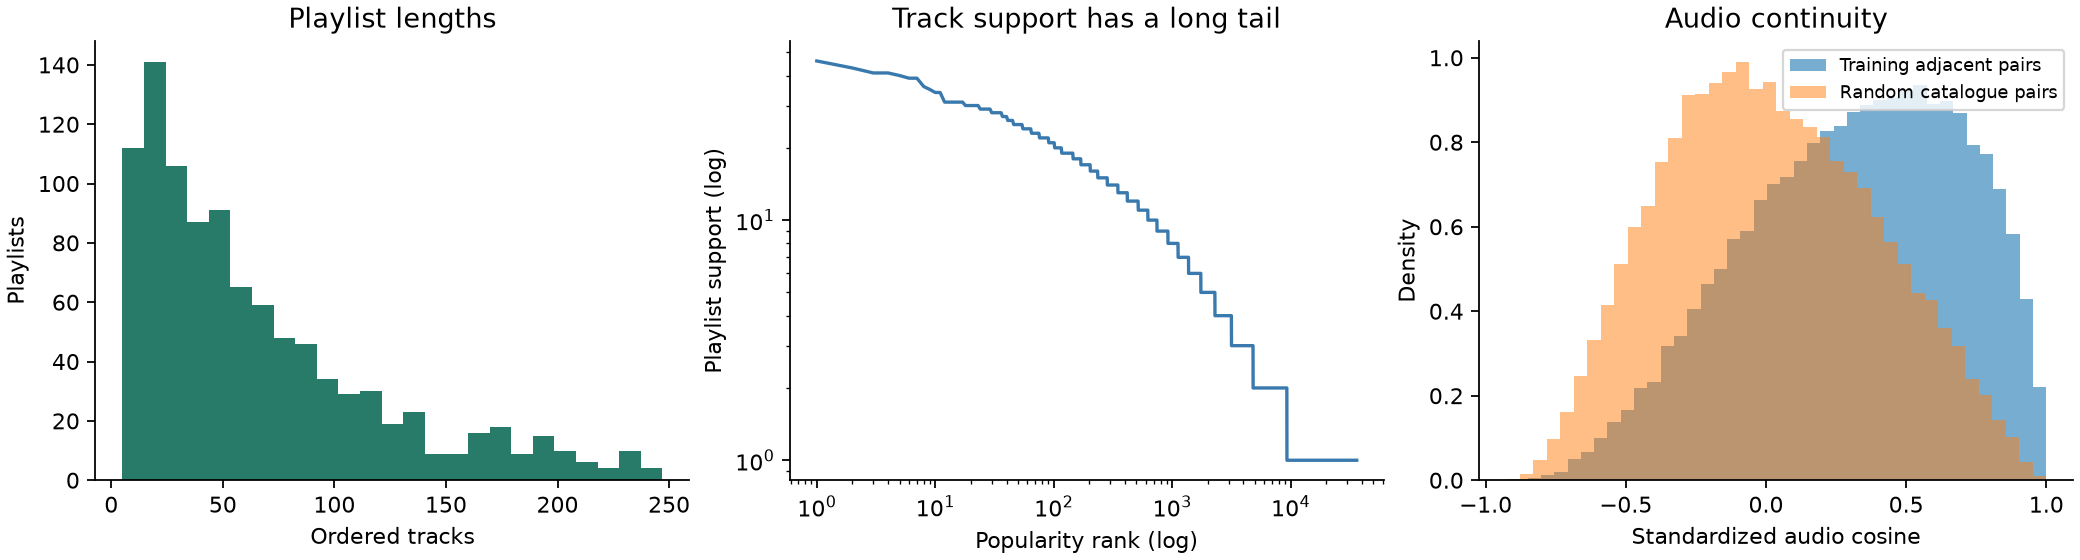

In [3]:
data = prepare_data()
s = data['summary']
overview = pd.DataFrame({
    'quantity':['Sequence rows','Playlists','Catalogue tracks','Artists','Repeated memberships retained',
                'Unique memberships','Singleton tracks'],
    'value':[s['rows'],s['playlists'],s['tracks'],s['artists'],s['repeat_memberships'],
             s['unique_memberships'],s['singleton_tracks']]})
display(overview)
display(pd.Series(s['playlist_size'],name='Ordered playlist length').round(2).to_frame())
display(pd.DataFrame({'split':list(data['split']),
                      'playlists':[len(p) for p in data['split'].values()],
                      'learning_or_evaluation_queries':list(s['query_counts'].values()),
                      'ineligible_openings':list(s['excluded_short_openings'].values())}))
display(Image(filename=str(OUT/'data_overview.png')))

In [4]:
display(Markdown(f"""
### 2.3 Observed structure and implications

There are **{s['rows']:,} ordered rows**, **{s['playlists']:,} playlists**,
**{s['tracks']:,} distinct tracks**, and **{s['artists']:,} artists.
The **{s['repeat_memberships']:,} repeated playlist-track memberships are retained**.
Only **{s['density']:.3%}** of possible playlist-track pairs are observed.
**{s['singleton_tracks']:,} tracks ({s['singleton_tracks']/s['tracks']:.1%})** appear
in just one playlist. A held-out playlist can therefore contain targets with no
training interactions even though their catalogue metadata are known.

Playlist lengths range from {int(s['playlist_size']['min'])} to
{int(s['playlist_size']['max'])} tracks, with median {s['playlist_size']['50%']:g}.
Training yields **{s['query_counts']['train']:,} overlapping windows**; validation
has **{s['query_counts']['validation']}** eligible opening queries and test has
**{s['query_counts']['test']}**. The validation exclusion of two short playlists
is a consequence of the fixed split, not a resampling decision.

Among adjacent **training** pairs, **{s['train_same_artist_transition_fraction']:.1%}**
share an artist. This motivates both a last-artist baseline and artist compatibility
features. Mean adjacent standardized-audio cosine is
**{s['train_adjacent_audio_cosine']:.3f}**, versus **{s['random_audio_cosine']:.3f}**
for random catalogue pairs. This motivates testing audio, but does not show that it
can identify the exact next track among thousands of plausible candidates.
"""))
display(pd.read_csv(OUT/'audio_summary.csv',index_col=0).round(3))
print('Missing values by column:', s['missing_by_column'])
print('Nonfinite raw audio values:', s['nonfinite_audio_values'])


### 2.3 Observed structure and implications

There are **66,263 ordered rows**, **1,000 playlists**,
**36,203 distinct tracks**, and **9,963 artists.
The **854 repeated playlist-track memberships are retained**.
Only **0.181%** of possible playlist-track pairs are observed.
**26,901 tracks (74.3%)** appear
in just one playlist. A held-out playlist can therefore contain targets with no
training interactions even though their catalogue metadata are known.

Playlist lengths range from 5 to
247 tracks, with median 49.5.
Training yields **49,402 overlapping windows**; validation
has **98** eligible opening queries and test has
**100**. The validation exclusion of two short playlists
is a consequence of the fixed split, not a resampling decision.

Among adjacent **training** pairs, **26.4%**
share an artist. This motivates both a last-artist baseline and artist compatibility
features. Mean adjacent standardized-audio cosine is
**0.309**, versus **0.015**
for random catalogue pairs. This motivates testing audio, but does not show that it
can identify the exact next track among thousands of plausible candidates.


,count,mean,std,min,25%,50%,75%,max
danceability,36203.0,0.576,0.171,0.0,0.467,0.588,0.700,0.988
energy,36203.0,0.628,0.234,0.0,0.475,0.665,0.817,0.999
loudness,36203.0,-7.945,4.507,-60.0,-9.497,-6.810,-5.027,1.589
speechiness,36203.0,0.086,0.092,0.0,0.035,0.047,0.089,0.949
acousticness,36203.0,0.271,0.306,0.0,0.020,0.131,0.465,0.996
instrumentalness,36203.0,0.097,0.248,0.0,0.000,0.000,0.006,0.997
liveness,36203.0,0.195,0.167,0.0,0.096,0.126,0.248,0.997
valence,36203.0,0.479,0.251,0.0,0.276,0.470,0.677,1.000
tempo,36203.0,121.208,29.398,0.0,97.968,120.462,139.993,248.060
duration_ms,36203.0,235145.987,77339.804,4120.0,194905.500,224720.000,262083.000,1943459.000


Missing values by column: {'Unnamed: 0': 0, 'pid': 0, 'pos': 0, 'artist_name': 0, 'track_uri': 0, 'artist_uri': 0, 'track_name': 0, 'album_uri': 0, 'duration_ms': 0, 'album_name': 0, 'danceability': 0, 'energy': 0, 'key': 0, 'loudness': 0, 'mode': 0, 'speechiness': 0, 'acousticness': 0, 'instrumentalness': 0, 'liveness': 0, 'valence': 0, 'tempo': 0, 'type': 0, 'id': 0, 'uri': 0, 'track_href': 0, 'analysis_url': 0, 'time_signature': 0, 'item': 0}
Nonfinite raw audio values: 0


### 2.4 Audio features and the information boundary

Use ten continuous descriptors: danceability, energy, loudness, speechiness,
acousticness, instrumentalness, liveness, valence, tempo, and duration. Duration is
log-transformed before standardization because its range is wide. A defensive median
imputer and standard scaler are fitted on **unique tracks appearing in training
playlists**, then applied to the entire catalogue. The supplied numerical inputs are
finite and complete. Zero-valued descriptors are retained as supplied; their upstream
meaning cannot be checked from this file. Key, mode, and time signature are omitted
from this predefined audio representation rather than imposing arbitrary ordinal
distances on those categories.

Track and artist URIs define stable categorical identities. No ordinal numeric ID
enters a linear predictor. IDs are used to look up matching identities, co-occurrences,
and transitions. Track/album names, album IDs, URL columns, and the CSV index column
are excluded from features; names appear only in readable examples. Position defines
the window but is not a predictor, so the model cannot memorize a position-5 label.

**Cross-fitting the relational features matters.** A training window's own playlist
contains its target, so computing its co-occurrence and transition features from that
playlist would expose part of its label. Four playlist folds avoid this: for windows
in a held fold, interaction statistics come only from the other 600 training
playlists. The audio scaler uses training-only static metadata. Validation and test
use statistics from all 800 training playlists, with no held-out playlist interactions.
This creates some feature-distribution shift from 600 to 800 support playlists,
which is a limitation of this economical cross-fitting design.

<a id="part-3"></a>
## 3 · Models, optimization, and implementation

### 3.1 Task formulation and model families

For a history $h=(i_0,i_1,i_2,i_3,i_4)$ and candidate track $j$, construct features
$\phi(h,j)$ and score $s(h,j)$. Sort all catalogue tracks by decreasing score.
Ties are resolved by **training playlist support**, then lexicographically sorted
track URI. Previously played tracks are not masked. This common deterministic
tie rule is especially consequential for cold tracks and sparse Markov transitions.

| Method | Score and information used | Purpose |
|---|---|---|
| Uniform random | Expected HR@K = K / catalogue size | Chance reference, reported analytically |
| Popularity | Number of distinct training playlists containing candidate | Stronger than guessing; ignores history |
| Last artist | Candidate shares the fifth track's artist, followed by popularity tie-break | Tests how much simple artist persistence explains |
| Item cosine | Mean candidate cosine similarity to five history tracks, using binary training-playlist columns | Course-style neighborhood collaborative filtering |
| Markov | $P(j\mid i_4)$ from adjacent training transitions, smoothed toward training popularity | First-order sequential model |
| Audio similarity | Cosine of candidate standardized audio to mean history audio | Content-based comparison, including zero-support tracks |
| Logistic: history | Popularity, item cosines, Markov evidence, repeat fraction | Learned history-only control |
| Logistic: history + artist | Same features plus artist identity compatibility and transitions | Main control before audio |
| Logistic: history + artist + audio | Same history/artist features plus audio compatibility | Primary treatment |

For track transitions, use add-prior smoothing with total mass one:
$P(j\mid i)=(n_{ij}+p_0(j))/(n_i+1)$, where
$p_0(j)=(\mathrm{support}(j)+1)/(\sum_k\mathrm{support}(k)+N)$.
Unseen predecessor rows back off to that smoothed popularity prior. The same
construction uses artist transitions for artist features. These are statistics of
curator ordering, not observed playback transitions.

The course recommendation slides [L1] motivate cosine co-occurrence and ranking
evaluation; classification slides [L2] motivate logistic likelihood, L2 regularization,
and a distinct validation set. Temporal slides [L3] motivate sliding windows and
sequential recommendation. The random-playlist split does not turn curator position
into a genuine timestamp or establish chronological generalization.

In [5]:
class TrainingStatistics:
    """Interaction statistics from an explicitly named set of training playlists."""
    def __init__(self,data,pids):
        self.pids=frozenset(int(p) for p in pids)
        self.n_items=len(data["tracks"])
        self.n_artists=data["n_artists"]
        self.artist_ids=data["artist_ids"]
        u=[]; items=[]; source=[]; target=[]
        for row,pid in enumerate(sorted(self.pids)):
            seq=data["sequences"][pid]
            unique=np.unique(seq)
            u.extend([row]*len(unique)); items.extend(unique)
            source.extend(seq[:-1]); target.extend(seq[1:])
        b=csr_matrix((np.ones(len(items),dtype=np.float32),(u,items)),shape=(len(self.pids),self.n_items))
        self.pop=np.asarray(b.sum(axis=0)).ravel()
        self.prior=(self.pop+1)/(self.pop.sum()+self.n_items)
        similarity=(b.T @ b).tocsr()
        denom=np.sqrt(np.maximum(self.pop,1))
        self.cosine=similarity.multiply(1/denom[:,None]).multiply(1/denom[None,:]).tocsr()
        self.transition=csr_matrix((np.ones(len(source),dtype=np.float32),(source,target)),shape=(self.n_items,self.n_items))
        self.transition_out=np.asarray(self.transition.sum(axis=1)).ravel()
        au=self.artist_ids[np.asarray(items)]
        ba=csr_matrix((np.ones(len(u),dtype=np.float32),(u,au)),shape=(len(self.pids),self.n_artists))
        ba.data[:]=1
        self.artist_pop=np.asarray(ba.sum(axis=0)).ravel()
        self.artist_prior=(self.artist_pop+1)/(self.artist_pop.sum()+self.n_artists)
        aa=self.artist_ids[np.asarray(source)]; ab=self.artist_ids[np.asarray(target)]
        self.artist_transition=csr_matrix((np.ones(len(aa),dtype=np.float32),(aa,ab)),shape=(self.n_artists,self.n_artists))
        self.artist_out=np.asarray(self.artist_transition.sum(axis=1)).ravel()


def sparse_lookup(matrix,rows,columns):
    values=matrix[rows,columns]
    return values.toarray() if issparse(values) else np.asarray(values)


def candidate_features(data,stats,histories,candidates):
    """Return [query, candidate, feature], without receiving any target labels."""
    h=np.asarray(histories,dtype=int)
    c=np.asarray(candidates,dtype=int)
    if c.ndim==1: c=np.broadcast_to(c,(len(h),len(c)))
    q,n=c.shape
    sim=np.stack([sparse_lookup(stats.cosine,h[:,j,None],c) for j in range(5)],axis=-1)
    trans=np.stack([(sparse_lookup(stats.transition,h[:,j,None],c)+stats.prior[c]) /
                    (stats.transition_out[h[:,j,None]]+1) for j in range(5)],axis=-1)
    features=[np.log1p(stats.pop[c]),sim.mean(axis=-1),sim.max(axis=-1),sim[:,:,-1],
              np.log(trans[:,:,-1]),np.log(trans.mean(axis=-1)),(h[:,None,:]==c[:,:,None]).mean(axis=-1)]
    ha=data["artist_ids"][h]; ca=data["artist_ids"][c]
    at=np.stack([(sparse_lookup(stats.artist_transition,ha[:,j,None],ca)+stats.artist_prior[ca]) /
                 (stats.artist_out[ha[:,j,None]]+1) for j in range(5)],axis=-1)
    features += [(ha[:,-1,None]==ca).astype(float),(ha[:,None,:]==ca[:,:,None]).mean(axis=-1),
                 np.log1p(stats.artist_pop[ca]),np.log(at[:,:,-1]),np.log(at.mean(axis=-1))]
    z=data["z"]; zn=data["zn"]
    centroid=z[h].mean(axis=1)
    unit_centroid=normalize(centroid)
    last=z[h[:,-1]]
    features += [np.sum(zn[c]*zn[h[:,-1,None]],axis=-1),
                 np.sum(zn[c]*unit_centroid[:,None,:],axis=-1),
                 np.sqrt(np.sum((z[c]-last[:,None,:])**2,axis=-1)),
                 np.sqrt(np.sum((z[c]-centroid[:,None,:])**2,axis=-1))]
    diff=np.abs(z[c]-last[:,None,:])
    features += [diff[:,:,j] for j in range(len(AUDIO_COLUMNS))]
    result=np.stack(features,axis=-1).astype(np.float32)
    assert result.shape==(q,n,len(FEATURE_NAMES)) and np.isfinite(result).all()
    return result

In [6]:
display(pd.DataFrame({
    'group':['History','Artist','Audio'],
    'number_of_features':[len(HISTORY_NAMES),len(ARTIST_NAMES),len(AUDIO_NAMES)],
    'features':[', '.join(HISTORY_NAMES),', '.join(ARTIST_NAMES),', '.join(AUDIO_NAMES)]}))

,group,number_of_features,features
0,History,7,"log_track_support, cosine_mean, cosine_max, co..."
1,Artist,5,"same_last_artist, history_artist_fraction, log..."
2,Audio,14,"audio_cosine_last, audio_cosine_centroid, audi..."


### 3.2 The controlled feature comparison

The history group has **7 features**: log candidate playlist support; mean, maximum,
and last-track item cosine; log smoothed next-track probability from the last track;
log mean transition probability from the five history tracks; and the fraction of
history positions containing the candidate itself.

The artist group adds **5 features**: same artist as the last track; fraction of
history positions matching the candidate artist; log artist playlist support; and
last/mean smoothed artist transition log probabilities. The model uses compatibility
with artist IDs, not a coefficient for each artist. This can generalize to a catalogue
artist that did not occur in a training window.

The audio group adds **14 features**: last-track and centroid cosine, last-track and
centroid Euclidean distance in standardized descriptor space, and ten absolute
descriptor differences from the last track. A linear coefficient can learn whether
closeness in a particular descriptor helps. Low-dimensional descriptors do not encode
lyrics, language, cultural theme, genre labels, or a learned audio embedding.

The comparison is nested: history uses 7, history+artist 12, and history+artist+audio
26 candidate features. All configurations share windows, sampled candidates, weights,
optimizer, and full-catalogue evaluation. Each feature configuration independently
selects C on validation HR@10; this compares equally tuned pipelines rather than
holding the fitted coefficients or regularization fixed.

### 3.3 Learning objective and negative sampling

For every training window, the observed successor is one positive example. Ten
distinct tracks are drawn uniformly without replacement from the rest of the
catalogue as pseudo-negatives. Only the exact target is excluded: a prefix track may
be a candidate again. Other unobserved tracks may also be plausible successors, so
pseudo-negative does not mean disliked. No validation or test labels are used to
sample or reject training candidates.

The sampled binary logistic objective is

$$-\sum_e w_e[y_e\log\sigma(\beta^T\tilde\phi_e+b)
+(1-y_e)\log(1-\sigma(\beta^T\tilde\phi_e+b))]
+\lambda\|\beta\|_2^2,$$

where $\tilde\phi$ is standardized using training examples and $w_e$ gives every
training playlist equal total loss weight despite different numbers of windows.
Weights are normalized to mean one. Scikit-learn uses inverse regularization C;
the exact scaling convention follows that implementation. This is a **pointwise
logistic candidate scorer used for ranking**, not a listwise softmax or a pairwise
BPR loss. Scores from this 1:10 sampled problem are not calibrated probabilities
of being the next song in the full catalogue.

The fixed C grid is {0.01, 0.1, 1, 10}. L-BFGS optimizes each model with up to
500 iterations. A convergence warning is treated as a failure rather than silently
accepted. Validation HR@10 chooses C; an exact tie chooses the smaller C in the
declared grid. MRR and median rank do not break the primary-metric tie. The chosen
models remain fitted on the original training examples; no test-guided refit occurs.

In [7]:
def negative_candidates(data,queries,seed):
    """One observed target plus 10 distinct uniform unobserved candidate targets."""
    rng=np.random.default_rng(seed)
    target=queries.target.to_numpy()
    c=np.empty((len(queries),NEGATIVES+1),dtype=np.int32)
    c[:,0]=target
    for row,t in enumerate(target):
        # Draw distinct integers from N-1 and skip t, avoiding target collisions.
        sample=rng.choice(len(data["tracks"])-1,size=NEGATIVES,replace=False)
        c[row,1:]=sample+(sample>=t)
    return c


def training_examples(data):
    """Cross-fit relational features by playlist; include every training window."""
    q=data["queries"]["train"].reset_index(drop=True)
    candidates=negative_candidates(data,q,SEED+1)
    features=np.empty((len(q),NEGATIVES+1,len(FEATURE_NAMES)),dtype=np.float32)
    folds=np.array_split(data["split"]["train"],4)
    fold_manifest=[]
    for fold,held in enumerate(folds):
        fit=np.setdiff1d(data["split"]["train"],held)
        stats=TrainingStatistics(data,fit)
        assert not stats.pids.intersection(map(int,held))
        rows=np.flatnonzero(q.pid.isin(held))
        for first in range(0,len(rows),512):
            ix=rows[first:first+512]
            features[ix]=candidate_features(data,stats,q.iloc[ix][[f"h{j}" for j in range(5)]].to_numpy(),candidates[ix])
        fold_manifest.extend({"pid":int(pid),"held_fold":fold} for pid in held)
        print(f"Cross-fit fold {fold+1}/4: {len(rows):,} windows; statistics from {len(fit)} playlists",flush=True)
    pd.DataFrame(fold_manifest).to_csv(OUT / "training_feature_folds.csv",index=False)
    labels=np.zeros(candidates.shape,dtype=np.int8); labels[:,0]=1
    # Give every playlist equal total weight despite its number of overlapping windows.
    windows_per_playlist=q.groupby("pid").pid.transform("size").to_numpy()
    weights=np.repeat(1/windows_per_playlist,NEGATIVES+1)
    weights=weights/weights.mean()
    assert np.all(candidates[:,0,None]!=candidates[:,1:])
    return features.reshape(-1,len(FEATURE_NAMES)),labels.ravel(),weights


def query_features(data,stats,queries):
    catalog=np.arange(len(data["tracks"]))
    # At 100 openings, 100 x 36,203 x 26 float32 is about 377 MB.
    # Persist only small batches during evaluation, not this entire cube.
    for first in range(0,len(queries),4):
        block=queries.iloc[first:first+4]
        h=block[[f"h{j}" for j in range(5)]].to_numpy()
        yield first,candidate_features(data,stats,h,catalog)


def choose_models(data,stats,x,y,weights):
    q=data["queries"]["validation"]
    results=[]; models={}; best={}
    # Full-catalogue validation features are built once per block per C sweep.
    for name,columns in MODEL_FEATURES.items():
        best_key=None
        for c in REGULARIZATION:
            model=make_pipeline(StandardScaler(),LogisticRegression(C=c,solver="lbfgs",max_iter=500,random_state=SEED))
            start=perf_counter()
            with warnings.catch_warnings():
                warnings.simplefilter("error",ConvergenceWarning)
                model.fit(x[:,columns],y,logisticregression__sample_weight=weights)
            fit_seconds=perf_counter()-start
            ranks=[]
            for first,features in query_features(data,stats,q):
                scores=model.decision_function(features[:,:,columns].reshape(-1,len(columns))).reshape(features.shape[:2])
                for j,row in enumerate(q.iloc[first:first+len(features)].itertuples()):
                    ranks.append(rank_target(scores[j],row.target,stats.pop))
            metrics=ranking_metrics(ranks)
            row={"model":name,"C":c,"fit_seconds":fit_seconds,"iterations":int(model[-1].n_iter_[0]),**metrics}
            results.append(row)
            # Primary endpoint only; equal HR chooses the smaller C in the fixed grid.
            key=metrics["HR@10"]
            if best_key is None or key>best_key:
                best_key=key; models[name]=model; best[name]=row
            print(f"Validation {name}, C={c}: HR@10={metrics['HR@10']:.4f}, MRR@10={metrics['MRR@10']:.4f}",flush=True)
    table=pd.DataFrame(results)
    table.to_csv(OUT / "validation_grid.csv",index=False)
    (OUT / "frozen_selection.json").write_text(json.dumps(best,indent=2),encoding="utf-8")
    coef=[]
    for name,model in models.items():
        for j,col in enumerate(MODEL_FEATURES[name]):
            coef.append({"model":name,"feature":FEATURE_NAMES[col],"standardized_coefficient":float(model[-1].coef_[0,j])})
    pd.DataFrame(coef).to_csv(OUT / "coefficients.csv",index=False)
    return models,best,table

### 3.4 Tradeoffs, efficiency, and limitations

Artist and Markov rules are interpretable and cheap. Sparse transitions struggle with
unseen tracks; the popularity backoff often controls their rankings. Item cosine
aggregates five tracks and can exploit broader context, but it is also unsupported
for cold candidates. Audio can distinguish cold candidates yet may rank many
acoustically similar alternatives above the curator's exact choice.

The learned models combine these imperfect signals. L2 regularization, a small
predeclared feature set, and playlist-disjoint validation constrain overfitting.
Overlapping windows within training playlists are dependent; equal playlist weighting
reduces domination by long playlists, and evaluation uses one opening per playlist.
Uniform negatives are efficient but can make training easier than ranking among many
tracks by the same artist. Hard-negative experiments would be a separate, validation-
controlled study, not a change made after inspecting these test results.

Interactions, co-occurrences, and transitions use sparse matrices. Training candidates
require approximately 57 MB for the 26-column float32 feature array. Four-query
evaluation batches require about 15 MB for the final feature tensor, with additional
temporary arrays for audio and sparse lookups. The dense 100-query feature cube is
never retained. At full MPD scale even sparse co-occurrence construction can become
large; approximate candidate retrieval and a second-stage ranker would be appropriate.
This study avoids candidate pruning so every model competes over the same catalogue.

The models distinguish the last track from earlier history, but mean/max history
features are invariant to the order of the first four tracks. They are therefore
only partly order-sensitive. A higher-order Markov model or recurrent/attention model
could learn richer order, at greater data and optimization cost. Rating-MSE regression
is not the main comparison because no ratings are present; ordinary binary accuracy
would be dominated by the many unobserved pairs.

<a id="part-4"></a>
## 4 · Evaluation and controlled comparisons

### 4.1 Exact ranks, metrics, and uncertainty

If the unique observed next track has one-based rank $r_p$ among all $N$ candidates:

$$HR@K=\frac1P\sum_p\mathbf1[r_p\le K],\qquad
MRR@K=\frac1P\sum_p\frac{\mathbf1[r_p\le K]}{r_p}.$$

The main display reports **HR@10**, **MRR@10**, and **median rank**. HR answers
whether a listener sees the curator's exact next song in a ten-song list; MRR rewards
putting a hit earlier in that list. Median rank captures typical retrieval position
below the cutoff, but may improve while the visible list does not. With one target,
recall@K equals HR@K and precision@K equals HR@K divided by K, so those redundant
metrics are omitted. Cutoffs 1, 5, 20, 50, and 100 show descriptive sensitivity to
list length; they do not replace the preselected primary endpoint.

Every query ranks **all catalogue tracks, including repeated prefix tracks**. There
are no sampled evaluation negatives or support filters. Training-time negative
sampling reduces optimization cost; it does not reduce the evaluation catalogue.
This distinction matters because sampled ranking metrics can change model comparisons
[R4]. Uniform random is reported analytically: HR@10 = 10/N, expected MRR@10 is
$\sum_{r=1}^{10}1/rN$, and the median rank is (N+1)/2.

The primary difference is HR@10(with audio) minus HR@10(without audio), with artist
features in both. Resample the 100 paired test playlists **10,000 times** to obtain
a 95% percentile bootstrap interval. Also report gained and lost hits and the exact
two-sided McNemar/binomial test on discordant outcomes. Equal total hits need not
mean the same playlists succeed. Only this audio comparison is the confirmatory
comparison; other model and subgroup results are descriptive.

The interval is conditional on these fitted models and this single split. It does
not include uncertainty from retraining, hyperparameter selection, a different
playlist sample, or a changed catalogue. Shared songs and artists may correlate
playlist outcomes. One hundred test playlists give limited power to detect small
incremental effects, so a nonsignificant result does not establish equivalence.

In [8]:
def rank_target(scores,target,popularity):
    """1-based full-catalogue rank; ties use training support then track URI."""
    ids=np.arange(len(scores))
    score=scores[target]
    better=(scores>score)
    tie=scores==score
    better |= tie & (popularity>popularity[target])
    better |= tie & (popularity==popularity[target]) & (ids<target)
    return int(1+better.sum())


def ranking_metrics(ranks):
    r=np.asarray(ranks)
    result={"queries":len(r),"Median rank":float(np.median(r)),"Mean rank":float(np.mean(r)),
            "MRR":float(np.mean(1/r))}
    for k in [1,5,10,20,50,100]:
        result[f"Hits@{k}"]=int((r<=k).sum())
        result[f"HR@{k}"]=float(np.mean(r<=k))
        result[f"MRR@{k}"]=float(np.mean(np.where(r<=k,1/r,0)))
    return result


def evaluate_queries(data,stats,models,queries,label,save_examples=False):
    rows=[]; examples=[]
    for first,features in query_features(data,stats,queries):
        block=queries.iloc[first:first+len(features)]
        learned={name:model.decision_function(features[:,:,MODEL_FEATURES[name]].reshape(-1,len(MODEL_FEATURES[name]))).reshape(features.shape[:2])
                 for name,model in models.items()}
        for j,row in enumerate(block.itertuples()):
            h=np.array([getattr(row,f"h{k}") for k in range(5)])
            last_artist=data["artist_ids"][h[-1]]
            scores={"Popularity":stats.pop,
                    "Last artist":(data["artist_ids"]==last_artist).astype(float),
                    "Item cosine":features[j,:,1],"Markov":features[j,:,4],
                    "Audio similarity":features[j,:,13]}
            scores.update({name:values[j] for name,values in learned.items()})
            for name,s in scores.items():
                assert len(s)==len(data["tracks"]) and np.isfinite(s).all()
                rank=rank_target(s,row.target,stats.pop)
                rows.append({"experiment":label,"pid":int(row.pid),"start":int(row.start),"model":name,
                             "target":int(row.target),"rank":rank,"track_support":int(stats.pop[row.target]),
                             "same_last_artist":bool(data["artist_ids"][row.target]==last_artist),
                             "target_in_history":bool(row.target in h)})
                if save_examples:
                    ids=np.arange(len(s)); order=np.lexsort((ids,-stats.pop,-s))[:10]
                    for k,item in enumerate(order,1):
                        examples.append({"pid":int(row.pid),"model":name,"rank":k,"item":int(item),
                                         "is_target":int(item==row.target),"track":data["tracks"].iloc[item].track_name,
                                         "artist":data["tracks"].iloc[item].artist_name})
    details=pd.DataFrame(rows)
    table=pd.DataFrame([{"model":name,**ranking_metrics(g["rank"])} for name,g in details.groupby("model",sort=False)])
    details.to_csv(OUT / (label+"_per_query.csv"),index=False)
    table.to_csv(OUT / (label+"_metrics.csv"),index=False)
    if save_examples: pd.DataFrame(examples).to_csv(OUT / "test_top10.csv",index=False)
    return details,table


def paired_bootstrap(before,after):
    a=np.asarray(before); b=np.asarray(after)
    assert a.shape==b.shape
    rng=np.random.default_rng(2026)
    ix=rng.integers(0,len(a),size=(10000,len(a)))
    delta=(b<=10).astype(float)-(a<=10).astype(float)
    lo,hi=np.quantile(delta[ix].mean(axis=1),[.025,.975])
    gained=int(((b<=10)&(a>10)).sum()); lost=int(((a<=10)&(b>10)).sum())
    # Exact paired binary test; only discordant query outcomes count.
    p=binomtest(gained,gained+lost,.5).pvalue if gained+lost else 1.
    return {"delta_hr10":float(delta.mean()),"ci_low":float(lo),"ci_high":float(hi),
            "gained_hits":gained,"lost_hits":lost,"exact_mcnemar_p":float(p),
            "delta_mrr10":float(np.mean(np.where(b<=10,1/b,0)-np.where(a<=10,1/a,0))),
            "median_paired_rank_change":float(np.median(b-a)),"bootstrap_draws":10000}


def summarize_and_plot(data,stats,details,table,models,selection):
    subgroup=[]
    for name,g in details.groupby("model",sort=False):
        for support,sub in g.groupby(g.track_support.gt(0)):
            subgroup.append({"model":name,"support":"positive" if support else "zero",**ranking_metrics(sub["rank"])})
    subgroup=pd.DataFrame(subgroup)
    subgroup.to_csv(OUT / "test_support_metrics.csv",index=False)
    before=details[details.model=="History + artist"].set_index("pid").sort_index()
    after=details[details.model=="History + artist + audio"].set_index("pid").sort_index()
    assert before.index.equals(after.index)
    primary=paired_bootstrap(before["rank"],after["rank"])
    pairs=[]
    for pid in before.index:
        pairs.append({"pid":int(pid),"rank_without_audio":int(before.loc[pid,"rank"]),
                      "rank_with_audio":int(after.loc[pid,"rank"]),"track_support":int(before.loc[pid,"track_support"])})
    pd.DataFrame(pairs).to_csv(OUT / "audio_paired_ranks.csv",index=False)
    n=len(data["tracks"])
    random={"model":"Uniform random (expectation)","queries":len(before),"HR@10":10/n,
            "MRR@10":float(np.sum(1/np.arange(1,11))/n),"Median rank":(n+1)/2}
    # First test opening chosen by sorted pid, never by success.
    example_pid=int(data["queries"]["test"].pid.min())
    summary={"primary":primary,"frozen_selection":selection,"random_baseline":random,
             "test_queries":len(before),"zero_support_targets":int((before.track_support==0).sum()),
             "test_same_last_artist_fraction":float(before.same_last_artist.mean()),
             "test_repeat_target_fraction":float(before.target_in_history.mean()),"example_pid":example_pid,
             "train_windows":len(data["queries"]["train"]),"negatives_per_window":NEGATIVES,
             "training_candidate_examples":len(data["queries"]["train"])*(NEGATIVES+1),
             "feature_names":FEATURE_NAMES,"environment":{"python":platform.python_version(),"numpy":np.__version__,
                "pandas":pd.__version__,"scipy":scipy.__version__,"sklearn":sklearn.__version__},
             "dataset_sha256":data["summary"]["dataset_sha256"]}
    (OUT / "experiment_summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
    names=table.model.to_list()
    colors=["#a3adb4"]*5+["#8bacbf","#297b69","#d18e3b"]
    fig,ax=plt.subplots(1,2,figsize=(13,4.5),layout="constrained")
    ax[0].barh(names,table["HR@10"],color=colors)
    ax[0].invert_yaxis();ax[0].set(xlabel="Exact sixth-track Hit Rate@10",title="What appears in a short list?")
    for i,value in enumerate(table["HR@10"]): ax[0].text(value+.003,i,f"{int(round(value*len(before)))}/{len(before)}",va="center",fontsize=8)
    ax[0].set_xlim(0,max(table["HR@10"])+.07)
    ax[1].barh(names,table["Median rank"],color=colors)
    ax[1].invert_yaxis(); ax[1].set(xlabel="Median target rank (log; lower is better)",xscale="log",title="What moves below the cutoff?")
    fig.savefig(OUT / "retrieval_comparison.png",dpi=170);plt.close(fig)
    fig,ax=plt.subplots(1,2,figsize=(11,3.6),layout="constrained")
    for name in MODEL_FEATURES:
        ranks=details.loc[details.model==name,"rank"].to_numpy()
        ks=np.array([1,5,10,20,50,100,500,1000])
        ax[0].plot(ks,[(ranks<=k).mean() for k in ks],marker="o",label=name)
    ax[0].set(xscale="log",xlabel="Recommendation cutoff K (log)",ylabel="Hit Rate@K",title="The useful cutoff changes the comparison")
    ax[0].legend(fontsize=8)
    lim=n+1
    for support,color in [(False,"#3979ad"),(True,"#d18e3b")]:
        mask=before.track_support.gt(0).to_numpy()==support
        ax[1].scatter(before["rank"].to_numpy()[mask],after["rank"].to_numpy()[mask],s=20,alpha=.7,
                      label="Positive support" if support else "Zero support",color=color)
    ax[1].plot([1,lim],[1,lim],color="gray",linestyle="--")
    ax[1].set(xscale="log",yscale="log",xlabel="Rank without audio",ylabel="Rank with audio",title="Below diagonal: audio improves rank")
    ax[1].legend(fontsize=8)
    fig.savefig(OUT / "audio_ablation.png",dpi=170);plt.close(fig)
    return summary,subgroup


def sensitivity_checks(data,stats,models):
    openings=data["queries"]["test"].copy()
    history=[f"h{j}" for j in range(5)]
    reversed_q=openings.copy()
    reversed_q[history]=openings[history].to_numpy()[:,::-1]
    _,reverse_table=evaluate_queries(data,stats,models,reversed_q,"sensitivity_reverse")
    # An exact invariance diagnostic: internal first-four order is not represented.
    permuted=openings.copy()
    permuted[history]=openings[history].to_numpy()[:,[3,1,0,2,4]]
    _,permuted_table=evaluate_queries(data,stats,models,permuted,"sensitivity_first4")
    later=queries_from_sequences(data["sequences"],data["split"]["test"],start=5)
    _,later_table=evaluate_queries(data,stats,models,later,"sensitivity_later")
    matched=openings[openings.pid.isin(later.pid)].reset_index(drop=True)
    _,matched_table=evaluate_queries(data,stats,models,matched,"sensitivity_matched_openings")
    parts=[]
    for label,t in [("Reversed five",reverse_table),("First four permuted; last fixed",permuted_table),
                    ("Positions 5-9 -> 10",later_table),("Opening, matched later playlists",matched_table)]:
        parts.append(t.assign(setting=label))
    table=pd.concat(parts,ignore_index=True)
    table.to_csv(OUT / "sensitivity_metrics.csv",index=False)
    return table


def run_experiment(data=None):
    if data is None: data=prepare_data()
    stats=TrainingStatistics(data,data["split"]["train"])
    assert not stats.pids.intersection(map(int,data["split"]["validation"]))
    assert not stats.pids.intersection(map(int,data["split"]["test"]))
    x,y,weights=training_examples(data)
    print(f"Fitting {len(y):,} sampled candidates with {x.shape[1]} features",flush=True)
    models,selection,validation=choose_models(data,stats,x,y,weights)
    # All model fitting and selection is finished before test labels are evaluated.
    details,table=evaluate_queries(data,stats,models,data["queries"]["test"],"test",save_examples=True)
    summary,subgroup=summarize_and_plot(data,stats,details,table,models,selection)
    sensitivity=sensitivity_checks(data,stats,models)
    print(table[["model","HR@10","MRR@10","Median rank"]].to_string(index=False),flush=True)
    print("Primary paired comparison:",json.dumps(summary["primary"]),flush=True)
    return {"data":data,"stats":stats,"models":models,"selection":selection,"validation":validation,
            "details":details,"table":table,"summary":summary,"subgroup":subgroup,"sensitivity":sensitivity}

In [9]:
results = run_experiment(data)
table = results['table']
summary = results['summary']
primary = summary['primary']
display(Markdown('### 4.2 Validation grid and frozen configurations'))
display(results['validation'][['model','C','HR@10','MRR@10','Median rank','iterations','fit_seconds']].round(5))
display(pd.DataFrame(results['selection']).T[['C','HR@10','MRR@10']])

Cross-fit fold 1/4: 13,068 windows; statistics from 600 playlists


Cross-fit fold 2/4: 12,456 windows; statistics from 600 playlists


Cross-fit fold 3/4: 11,472 windows; statistics from 600 playlists


Cross-fit fold 4/4: 12,406 windows; statistics from 600 playlists


Fitting 543,422 sampled candidates with 26 features


Validation History, C=0.01: HR@10=0.0510, MRR@10=0.0186


... (12 outputs left out)

Primary paired comparison: {"delta_hr10": 0.04, "ci_low": 0.01, "ci_high": 0.08, "gained_hits": 4, "lost_hits": 0, "exact_mcnemar_p": 0.125, "delta_mrr10": 0.020444444444444442, "median_paired_rank_change": -3.0, "bootstrap_draws": 10000}


### 4.2 Validation grid and frozen configurations

,model,C,HR@10,MRR@10,Median rank,iterations,fit_seconds
0,History,0.01,0.05102,0.01862,10764.0,13,0.28302
1,History,0.10,0.05102,0.01862,10764.0,13,0.26679
2,History,1.00,0.05102,0.01862,10764.0,13,0.27314
3,History,10.00,0.05102,0.01862,10764.0,13,0.26489
4,History + artist,0.01,0.14286,0.04719,1089.5,16,0.36627
5,History + artist,0.10,0.14286,0.04583,1098.5,16,0.36991
6,History + artist,1.00,0.14286,0.04583,1098.5,16,0.36414
7,History + artist,10.00,0.14286,0.04583,1098.5,16,0.37347
8,History + artist + audio,0.01,0.12245,0.05469,1322.0,24,0.86163
9,History + artist + audio,0.10,0.12245,0.05469,1328.0,27,0.89527


,C,HR@10,MRR@10
History,0.01,0.05102,0.018622
History + artist,0.01,0.142857,0.04719
History + artist + audio,0.01,0.122449,0.054689


### 4.3 Test openings: full-catalogue ranking

,model,queries,Hits@10,HR@10,MRR@10,Median rank
0,Uniform random (expectation),100,NaN,0.000276,0.000081,18102.0
1,Popularity,100,0.0,0.000000,0.000000,4097.5
2,Last artist,100,21.0,0.210000,0.088373,1416.0
3,Item cosine,100,4.0,0.040000,0.006524,2710.5
4,Markov,100,8.0,0.080000,0.038667,3453.5
5,Audio similarity,100,1.0,0.010000,0.010000,6638.5
6,History,100,6.0,0.060000,0.013429,2659.5
7,History + artist,100,18.0,0.180000,0.062107,552.0
8,History + artist + audio,100,22.0,0.220000,0.082552,611.5


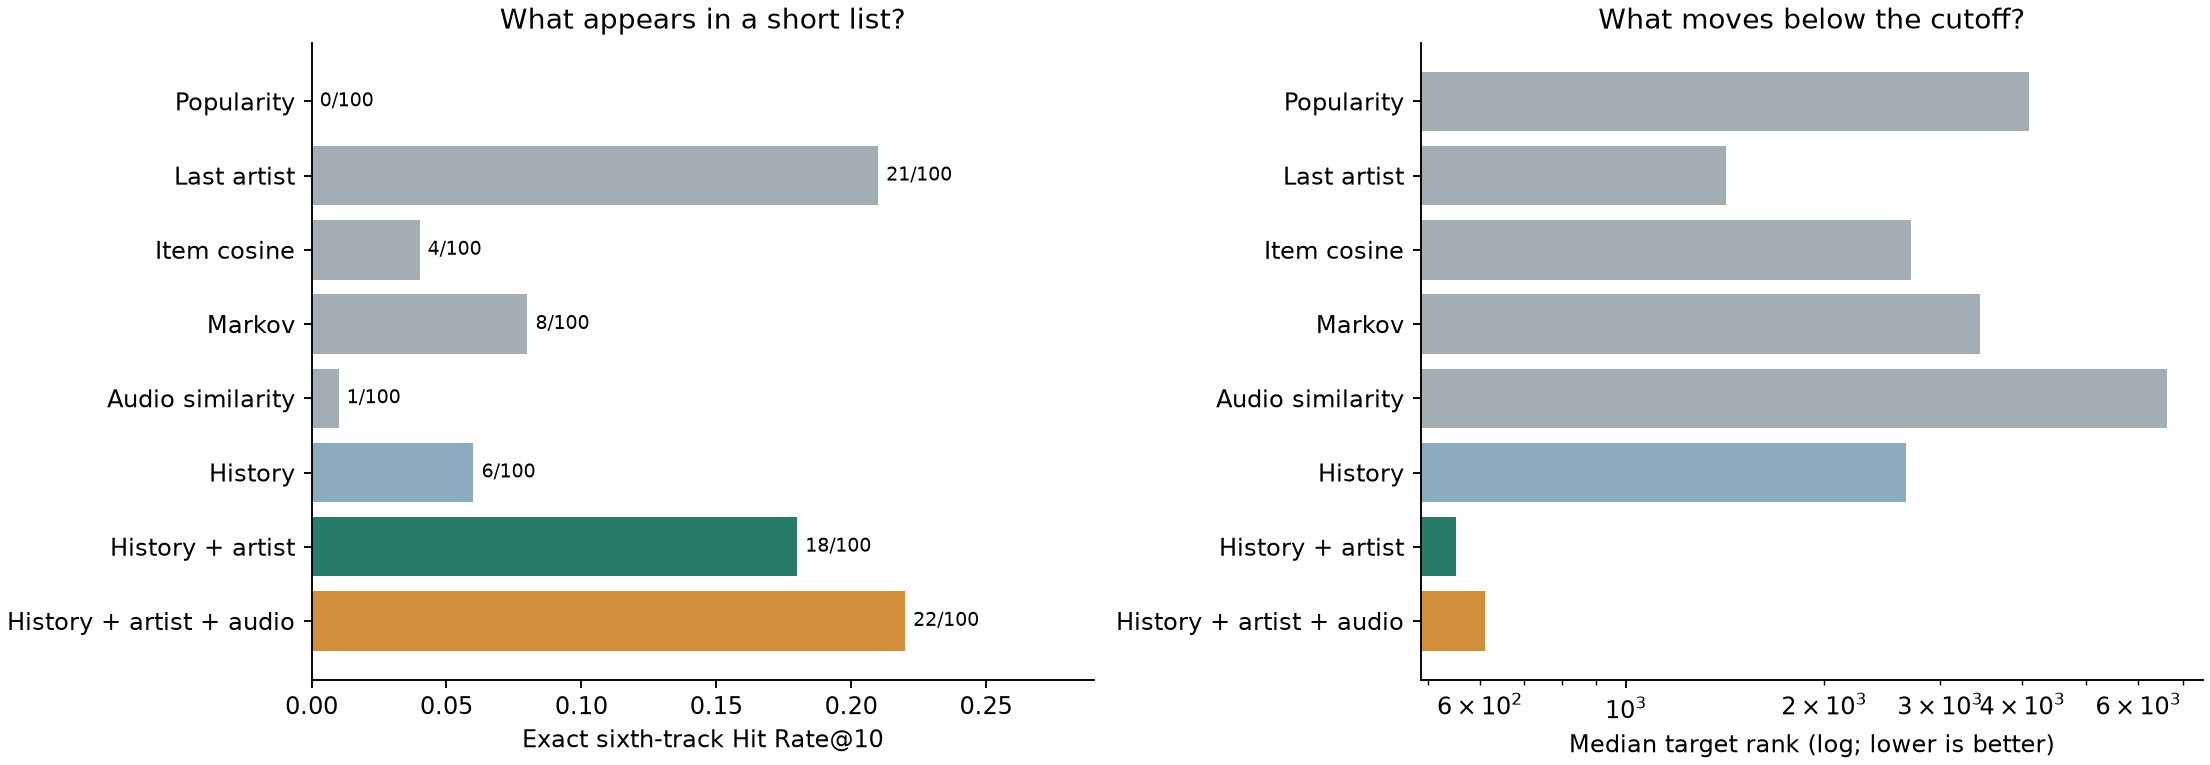

,"Audio minus no-audio, with artist in both"
delta_hr10,0.040000
ci_low,0.010000
ci_high,0.080000
gained_hits,4.000000
lost_hits,0.000000
exact_mcnemar_p,0.125000
delta_mrr10,0.020444
median_paired_rank_change,-3.000000
bootstrap_draws,10000.000000


,model,HR@1,HR@5,HR@10,HR@20,HR@50,HR@100,MRR@10,MRR
0,Popularity,0.00,0.00,0.00,0.00,0.01,0.02,0.00000,0.00118
1,Last artist,0.05,0.16,0.21,0.25,0.26,0.27,0.08837,0.09228
2,Item cosine,0.00,0.01,0.04,0.05,0.08,0.08,0.00652,0.00935
3,Markov,0.02,0.07,0.08,0.08,0.08,0.10,0.03867,0.03974
4,Audio similarity,0.01,0.01,0.01,0.01,0.03,0.06,0.01000,0.01179
5,History,0.00,0.03,0.06,0.10,0.11,0.15,0.01343,0.01777
6,History + artist,0.03,0.13,0.18,0.29,0.32,0.32,0.06211,0.07084
7,History + artist + audio,0.03,0.14,0.22,0.27,0.31,0.35,0.08255,0.08893


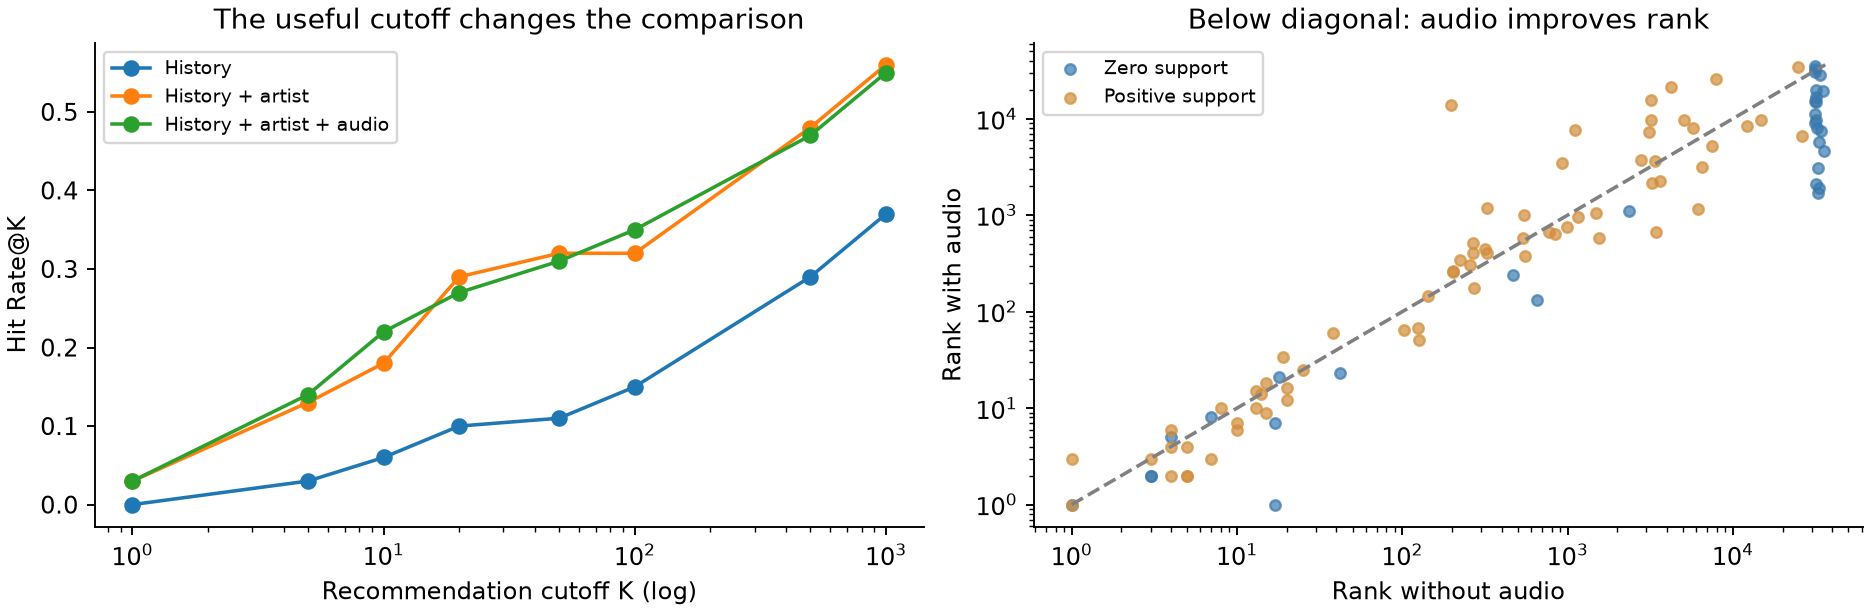

In [10]:
display(Markdown('### 4.3 Test openings: full-catalogue ranking'))
random_row = summary['random_baseline']
view = table[['model','queries','Hits@10','HR@10','MRR@10','Median rank']].copy()
display(pd.concat([pd.DataFrame([random_row]).reindex(columns=view.columns),view],ignore_index=True).round(6))
display(Image(filename=str(OUT/'retrieval_comparison.png')))
display(pd.Series(primary,name='Audio minus no-audio, with artist in both').to_frame())
display(table[['model','HR@1','HR@5','HR@10','HR@20','HR@50','HR@100','MRR@10','MRR']].round(5))
display(Image(filename=str(OUT/'audio_ablation.png')))

In [11]:
scores = table.set_index('model')
noaudio = scores.loc['History + artist']
audio = scores.loc['History + artist + audio']
lastartist = scores.loc['Last artist']
history = scores.loc['History']
direction = 'increases' if primary['delta_hr10'] > 0 else ('decreases' if primary['delta_hr10'] < 0 else 'does not change')
evidence = ('The exact paired test supports an audio gain at the 5% level.'
            if primary['exact_mcnemar_p'] < .05 and primary['delta_hr10'] > 0 else
            ('The exact paired test supports omitting audio at the 5% level.'
             if primary['exact_mcnemar_p'] < .05 and primary['delta_hr10'] < 0 else
             'The exact paired test does not establish a reliable difference at the 5% level; this does not establish equivalence.'))
display(Markdown(f"""
**Result in this sample.** The last-artist rule recovers **{int(lastartist['Hits@10'])} of
{int(lastartist['queries'])}** sixth songs. The learned history-only model recovers
**{int(history['Hits@10'])}**; history plus artist recovers **{int(noaudio['Hits@10'])}**;
and adding audio recovers **{int(audio['Hits@10'])}**. The supplied planning text's
23/24/24 figures are not hardcoded or treated as results of this implementation.

Adding audio **{direction}** observed HR@10 by **{primary['delta_hr10']:+.1%}**
(95% paired interval **[{primary['ci_low']:+.1%}, {primary['ci_high']:+.1%}]**).
There are **{primary['gained_hits']} gained** and **{primary['lost_hits']} lost** hits;
the exact paired test gives **p = {primary['exact_mcnemar_p']:.4f}**.
{evidence} MRR@10 changes from **{noaudio['MRR@10']:.4f}** to
**{audio['MRR@10']:.4f}**, so even equal HR would not imply equal ordering of hits.

Median target rank changes from **{noaudio['Median rank']:,.1f}** to
**{audio['Median rank']:,.1f}**. The median paired rank change is separately
**{primary['median_paired_rank_change']:,.1f}** (negative favors audio); a change in
the difference of medians is not the median of paired differences. These rank
summaries and the cutoff curve address a different question from top-ten success.
"""))
if primary['ci_low'] > 0 and primary['exact_mcnemar_p'] >= .05:
    display(Markdown("""
**Why the interval and test disagree here.** The plug-in percentile bootstrap
resamples only the observed query outcomes. With four gains and no losses it cannot
generate evidence of a loss, and its lower percentile can be positive even with very
few discordant queries. It can therefore be overconfident near this sparse boundary.
The exact paired test asks how surprising four wins out of four discordant outcomes
would be under equal win/loss chances; its two-sided p-value is 0.125. We retain both
requested diagnostics and do **not** use the positive bootstrap interval alone to
claim an established audio gain.
"""))


**Result in this sample.** The last-artist rule recovers **21 of
100** sixth songs. The learned history-only model recovers
**6**; history plus artist recovers **18**;
and adding audio recovers **22**. The supplied planning text's
23/24/24 figures are not hardcoded or treated as results of this implementation.

Adding audio **increases** observed HR@10 by **+4.0%**
(95% paired interval **[+1.0%, +8.0%]**).
There are **4 gained** and **0 lost** hits;
the exact paired test gives **p = 0.1250**.
The exact paired test does not establish a reliable difference at the 5% level; this does not establish equivalence. MRR@10 changes from **0.0621** to
**0.0826**, so even equal HR would not imply equal ordering of hits.

Median target rank changes from **552.0** to
**611.5**. The median paired rank change is separately
**-3.0** (negative favors audio); a change in
the difference of medians is not the median of paired differences. These rank
summaries and the cutoff curve address a different question from top-ten success.



**Why the interval and test disagree here.** The plug-in percentile bootstrap
resamples only the observed query outcomes. With four gains and no losses it cannot
generate evidence of a loss, and its lower percentile can be positive even with very
few discordant queries. It can therefore be overconfident near this sparse boundary.
The exact paired test asks how surprising four wins out of four discordant outcomes
would be under equal win/loss chances; its two-sided p-value is 0.125. We retain both
requested diagnostics and do **not** use the positive bootstrap interval alone to
claim an established audio gain.


In [12]:
display(Markdown('### 4.4 Zero versus positive training support'))
display(results['subgroup'][['model','support','queries','Hits@10','HR@10','MRR@10','Median rank']].round(5))
display(Markdown(f"""
**{summary['zero_support_targets']} of {summary['test_queries']}** test targets have
zero training playlist support. Their static artist and audio metadata are still
available. Track co-occurrence and transitions cannot provide positive item evidence
for them, although artist matching and content similarity may help. 'Unseen' below
means zero training interactions, not an unavailable or newly released track.

In these openings, the target shares the last artist in
**{summary['test_same_last_artist_fraction']:.1%}** of queries and repeats a prefix
track in **{summary['test_repeat_target_fraction']:.1%}**. These are test diagnostics,
not feature-selection criteria.
"""))
paired = pd.read_csv(OUT/'audio_paired_ranks.csv')
display(paired.assign(support=np.where(paired.track_support>0,'positive','zero')).groupby('support').agg(
    queries=('pid','size'),median_rank_without_audio=('rank_without_audio','median'),
    median_rank_with_audio=('rank_with_audio','median')))

### 4.4 Zero versus positive training support

,model,support,queries,Hits@10,HR@10,MRR@10,Median rank
0,Popularity,zero,32,0,0.00000,0.00000,33387.0
1,Popularity,positive,68,0,0.00000,0.00000,1638.5
2,Last artist,zero,32,5,0.15625,0.06076,32718.5
3,Last artist,positive,68,16,0.23529,0.10137,863.0
4,Item cosine,zero,32,0,0.00000,0.00000,33387.0
5,Item cosine,positive,68,4,0.05882,0.00959,811.5
6,Markov,zero,32,0,0.00000,0.00000,33387.0
7,Markov,positive,68,8,0.11765,0.05686,1383.5
8,Audio similarity,zero,32,1,0.03125,0.03125,3738.0
9,Audio similarity,positive,68,0,0.00000,0.00000,7873.5



**32 of 100** test targets have
zero training playlist support. Their static artist and audio metadata are still
available. Track co-occurrence and transitions cannot provide positive item evidence
for them, although artist matching and content similarity may help. 'Unseen' below
means zero training interactions, not an unavailable or newly released track.

In these openings, the target shares the last artist in
**26.0%** of queries and repeats a prefix
track in **0.0%**. These are test diagnostics,
not feature-selection criteria.


,queries,median_rank_without_audio,median_rank_with_audio
support,,,
positive,68,269.0,406.5
zero,32,31442.5,3882.5


### 4.5 Sensitivity to order and position

These are predefined secondary stress checks with **frozen** models and the same
training statistics. Their results do not trigger tuning.

1. **Order:** reverse all five visible tracks, keeping the original sixth-track
   label. This changes which track is last as well as order; any difference measures
   sensitivity to that combined perturbation, not pure internal-order understanding.
   Also permute the first four while keeping the fifth fixed. The current models
   are invariant to that permutation by construction; verify it numerically.
2. **Position:** use positions 5-9 to predict position 10 in playlists long enough
   to supply it. Compare against openings from those **same eligible playlists**.
   Differences reflect both query position and target composition, and cannot be
   attributed causally to position alone. Each condition uses one query per playlist.

In [13]:
sensitivity = results['sensitivity']
display(sensitivity[['setting','model','queries','HR@10','MRR@10','Median rank']].round(5))
original = results['details'].sort_values(['model','pid'])['rank'].to_numpy()
permuted = pd.read_csv(OUT/'sensitivity_first4_per_query.csv').sort_values(['model','pid'])['rank'].to_numpy()
assert np.array_equal(original,permuted)
print('Verified exact rank invariance when only the first four tracks are permuted.')
sens = sensitivity.set_index(['setting','model'])
display(Markdown(f"""
**Observed sensitivity.** Reversing all five tracks changes last-artist HR@10 from
**{lastartist['HR@10']:.1%}** to **{sens.loc[('Reversed five','Last artist'),'HR@10']:.1%}**;
the audio-augmented ranker changes from **{audio['HR@10']:.1%}** to
**{sens.loc[('Reversed five','History + artist + audio'),'HR@10']:.1%}**.
In contrast, permuting the first four while fixing the last changes no target ranks.
This supports sensitivity to the **last-track anchor**, not the ability to model
the internal order of the whole prefix.

There are **{int(sens.loc[('Positions 5-9 -> 10','History + artist'),'queries'])}**
eligible later-window playlists. On that matched subset, history-plus-artist HR@10
changes from **{sens.loc[('Opening, matched later playlists','History + artist'),'HR@10']:.1%}**
at the opening to **{sens.loc[('Positions 5-9 -> 10','History + artist'),'HR@10']:.1%}**
at the later position; the audio model changes from
**{sens.loc[('Opening, matched later playlists','History + artist + audio'),'HR@10']:.1%}**
to **{sens.loc[('Positions 5-9 -> 10','History + artist + audio'),'HR@10']:.1%}**.
Opening performance therefore does not transfer unchanged to later contexts.
"""))

Verified exact rank invariance when only the first four tracks are permuted.


,setting,model,queries,HR@10,MRR@10,Median rank
0,Reversed five,Popularity,100,0.00000,0.00000,4097.5
1,Reversed five,Last artist,100,0.07000,0.02850,2501.5
2,Reversed five,Item cosine,100,0.04000,0.00652,2710.5
3,Reversed five,Markov,100,0.01000,0.00250,4100.5
4,Reversed five,Audio similarity,100,0.01000,0.01000,6638.5
5,Reversed five,History,100,0.07000,0.01104,2645.5
6,Reversed five,History + artist,100,0.12000,0.03294,559.0
7,Reversed five,History + artist + audio,100,0.16000,0.05458,610.0
8,First four permuted; last fixed,Popularity,100,0.00000,0.00000,4097.5
9,First four permuted; last fixed,Last artist,100,0.21000,0.08837,1416.0



**Observed sensitivity.** Reversing all five tracks changes last-artist HR@10 from
**21.0%** to **7.0%**;
the audio-augmented ranker changes from **22.0%** to
**16.0%**.
In contrast, permuting the first four while fixing the last changes no target ranks.
This supports sensitivity to the **last-track anchor**, not the ability to model
the internal order of the whole prefix.

There are **97**
eligible later-window playlists. On that matched subset, history-plus-artist HR@10
changes from **18.6%**
at the opening to **8.2%**
at the later position; the audio model changes from
**22.7%**
to **14.4%**.
Opening performance therefore does not transfer unchanged to later contexts.


In [14]:
display(Markdown('### 4.6 Interpreting the fitted feature weights'))
coefficients = pd.read_csv(OUT/'coefficients.csv')
for name in MODEL_FEATURES:
    c = coefficients[coefficients.model==name].copy()
    c['absolute_weight'] = c.standardized_coefficient.abs()
    display(c.sort_values('absolute_weight',ascending=False).head(8).drop(columns='absolute_weight'))

### 4.6 Interpreting the fitted feature weights

,model,feature,standardized_coefficient
1,History,cosine_mean,0.704218
5,History,log_markov_mean,0.237814
0,History,log_track_support,-0.166634
4,History,log_markov_last,0.096119
3,History,cosine_last,0.095125
6,History,repeat_fraction,0.045982
2,History,cosine_max,0.021912


,model,feature,standardized_coefficient
15,History + artist,history_artist_fraction,1.034796
18,History + artist,log_artist_markov_mean,0.654391
8,History + artist,cosine_mean,0.545446
14,History + artist,same_last_artist,0.394183
16,History + artist,log_artist_support,-0.365626
7,History + artist,log_track_support,0.195954
9,History + artist,cosine_max,0.044186
10,History + artist,cosine_last,0.041486


,model,feature,standardized_coefficient
27,History + artist + audio,history_artist_fraction,0.899116
30,History + artist + audio,log_artist_markov_mean,0.589785
33,History + artist + audio,audio_distance_last,0.551133
32,History + artist + audio,audio_cosine_centroid,0.516985
20,History + artist + audio,cosine_mean,0.471341
34,History + artist + audio,audio_distance_centroid,-0.418943
28,History + artist + audio,log_artist_support,-0.378586
26,History + artist + audio,same_last_artist,0.370450


A standardized coefficient describes the conditional direction of the sampled
log-odds as that feature increases, holding the others fixed. Positive same-artist
weight is consistent with artist persistence; a negative distance coefficient is
consistent with preferring acoustic proximity. Correlated history, transition,
artist, and distance features can divide or reverse apparent importance, so weights
are not causal effects and are not directly comparable across differently tuned
models. The nested held-out comparison is stronger evidence of incremental value.

In [15]:
display(Markdown('### 4.7 A fixed example, with readable tracks'))
example_pid = summary['example_pid']
opening = data['queries']['test'].set_index('pid').loc[example_pid]
track_ids = opening[[f'h{k}' for k in range(5)]].to_numpy(dtype=int)
display(data['tracks'].iloc[track_ids][['track_name','artist_name']].assign(position=np.arange(5)))
display(data['tracks'].iloc[[int(opening.target)]][['track_name','artist_name']].assign(position=5))
example = pd.read_csv(OUT/'test_top10.csv')
display(example[(example.pid==example_pid)&example.model.isin(
    ['Last artist','History + artist','History + artist + audio'])])
print('Example playlist chosen by smallest test pid:', example_pid)

### 4.7 A fixed example, with readable tracks

,track_name,artist_name,position
20493,Middle,DJ Snake,0
29230,Old Thing Back (feat. Ja Rule and Ralph Tresvant),Matoma,1
10211,Comfortable,K CAMP,2
4939,SummerThing!,Afrojack,3
29602,MATANGI,M.I.A.,4


,track_name,artist_name,position
1857,All We Know,Brevner,5


,pid,model,rank,item,is_target,track,artist
1690,1,Last artist,1,8146,0,Paper Planes,M.I.A.
1691,1,Last artist,2,31175,0,Bad Girls,M.I.A.
1692,1,Last artist,3,4871,0,Y.A.L.A.,M.I.A.
1693,1,Last artist,4,27512,0,Sunshowers,M.I.A.
1694,1,Last artist,5,34762,0,XXXO,M.I.A.
1695,1,Last artist,6,5165,0,It Takes A Muscle,M.I.A.
1696,1,Last artist,7,19582,0,World Town,M.I.A.
1697,1,Last artist,8,29602,0,MATANGI,M.I.A.
1698,1,Last artist,9,34087,0,HUMBLE.,Kendrick Lamar
1699,1,Last artist,10,26256,0,Ignition - Remix,R. Kelly


Example playlist chosen by smallest test pid: 1


<a id="part-5"></a>
## 5 · Findings, related work, and conclusions

### 5.1 What prior work contributes

**Dataset and continuation context.** Spotify's MPD announcement [R1] establishes
the original dataset's continuation purpose. Zamani et al.'s challenge analysis [R2]
studies recommendation of fitting additions from seed playlists and metadata. The
present task is narrower: one exact immediate successor after five ordered tracks,
100 test openings, and a much smaller catalogue. Official MPD challenge numbers
must not be used as a directly comparable benchmark.

**Context versus order.** Vall et al. [R3] compare popularity, collaborative filtering,
and recurrent models on curated playlists. They find useful song-context signal,
while order is not crucial in their reported experiments. This motivates the
history comparisons and order stress checks here. Our rankers encode the last
track separately but do not learn the order of the earlier four tracks, so they
cannot establish that richer sequential modeling is unnecessary.

**Audio and hybrid recommendation.** Ferraro et al. [R5] combine audio/title-aware
factorization with co-occurrence evidence through ranking fusion. Their hybrid
motivates testing content alongside interaction features. The current features
are low-dimensional Spotify descriptors; they omit playlist titles and learned
audio representations. Weak incremental audio value here would not refute a richer
hybrid, especially with a different catalogue and relevance objective.

**Evaluation choice.** Krichene and Rendle [R4] show that sampled recommendation
metrics can change the relative comparison between algorithms. That supports full-
catalogue evaluation here. Sampled pseudo-negatives remain an optimization choice,
explicitly separate from evaluation candidates.

These are relevant established research comparisons, not a claim to reproduce a
current state-of-the-art system. A stronger next experiment could compare a sequential
attention/recurrent model and an audio-embedding hybrid under this same fixed protocol,
with enough playlist data and validation capacity to tune them fairly.

In [16]:
display(Markdown('### 5.2 What the current experiment supports'))
best_model = scores['HR@10'].idxmax()
best_score = scores.loc[best_model,'HR@10']
zero = results['subgroup'].query("support == 'zero'").set_index('model')
display(Markdown(f"""
The strongest observed top-ten result is **{best_model}**, with
**HR@10 = {best_score:.3f}**. This is a descriptive comparison across the reported
methods, not a new test-driven model-selection step. The main audio comparison
is between the two predeclared artist-aware pipelines, not between whichever two
models happen to rank highest on test.

Adding artist features changes the learned history-only model from
**{int(history['Hits@10'])}** to **{int(noaudio['Hits@10'])}** hits. The last-artist rule
alone obtains **{int(lastartist['Hits@10'])}** hits. Their proximity or difference
helps assess how much complexity buys beyond artist persistence. This is an
ablation association on held-out playlists, not a causal claim about artist identity.

Audio changes HR@10 by **{primary['delta_hr10']:+.1%}** with paired interval
**[{primary['ci_low']:+.1%}, {primary['ci_high']:+.1%}]**. {evidence}
For zero-support targets, median rank is
**{zero.loc['History + artist','Median rank']:,.1f}** without audio and
**{zero.loc['History + artist + audio','Median rank']:,.1f}** with audio.
The sign and size of that shift should be read alongside top-ten subgroup hits:
retrieval below the cutoff may matter for a large candidate pool, but does not
automatically help a listener who sees only ten songs.
"""))

### 5.2 What the current experiment supports


The strongest observed top-ten result is **History + artist + audio**, with
**HR@10 = 0.220**. This is a descriptive comparison across the reported
methods, not a new test-driven model-selection step. The main audio comparison
is between the two predeclared artist-aware pipelines, not between whichever two
models happen to rank highest on test.

Adding artist features changes the learned history-only model from
**6** to **18** hits. The last-artist rule
alone obtains **21** hits. Their proximity or difference
helps assess how much complexity buys beyond artist persistence. This is an
ablation association on held-out playlists, not a causal claim about artist identity.

Audio changes HR@10 by **+4.0%** with paired interval
**[+1.0%, +8.0%]**. The exact paired test does not establish a reliable difference at the 5% level; this does not establish equivalence.
For zero-support targets, median rank is
**31,442.5** without audio and
**3,882.5** with audio.
The sign and size of that shift should be read alongside top-ten subgroup hits:
retrieval below the cutoff may matter for a large candidate pool, but does not
automatically help a listener who sees only ten songs.


### 5.3 Practical interpretation and limits

Choose the objective before choosing the method. A ten-song interface should be
judged mainly by HR@10 and ordering of those hits. A later-stage candidate generator
may value rank improvements deeper in the catalogue, especially for zero-support
targets. These roles can favor different feature sets. A bigger list or better
median rank should not be presented as a top-ten gain.

This study is limited by uncertain file provenance, one coverage-aware split,
98 validation and 100 test openings, an assumed simultaneously available catalogue,
incomplete relevance labels, and sampled training candidates. Opening queries may
behave differently from arbitrary positions. There are no users, playback logs, or
dates with which to establish listener satisfaction or chronological generalization.
The out-of-fold training feature support differs from final support, and short
same-artist runs can reward artist rules without measuring musical variety.

The next evidence to collect is a larger playlist-disjoint test sample, repeated
predeclared splits with paired uncertainty, more realistic hard negatives, richer
audio/text representations, and a genuinely order-sensitive model. A listening study
or behavior logs would be needed to judge pleasant alternatives rather than exact
agreement with the curator's sixth song. These follow-up experiments are proposals;
none is reported as an achieved result.

### 5.4 References

- **[L1] Julian McAuley, _Recommender Systems_, course slides.**
  [Supplied recommendation slides](https://drive.google.com/file/d/1VAt1C5Za5JCBXUkeRbqkH8jajgTdfmnl/view).
  Cosine collaborative filtering, cold start, and ranking evaluation.
- **[L2] Julian McAuley, _Classification_, course slides.**
  [Supplied classification slides](https://drive.google.com/file/d/1fUrZCpQ6Sx92blcn6NshOPEWxb27Jp6k/view).
  Logistic learning, regularization, and validation.
- **[L3] Julian McAuley, _Temporal data mining_, course slides.**
  [Supplied temporal slides](https://drive.google.com/file/d/1YQdxP_boLqM24MEiXy65ii3Utiqp55R3/view).
  Sliding windows and sequential recommendation.
- **[R1] Ching-Wei Chen (2020), _The Million Playlist Dataset... Remastered_.**
  [Spotify Research](https://research.atspotify.com/2020/09/the-million-playlist-dataset-remastered).
- **[R2] Hamed Zamani, Markus Schedl, Paul Lamere, and Ching-Wei Chen (2019),
  _An Analysis of Approaches Taken in the ACM RecSys Challenge 2018 for Automatic
  Music Playlist Continuation_.** [Paper](https://arxiv.org/abs/1810.01520).
- **[R3] Andreu Vall, Massimo Quadrana, Markus Schedl, and Gerhard Widmer (2018),
  _The Importance of Song Context and Song Order in Automated Music Playlist
  Generation_.** [Paper](https://arxiv.org/abs/1807.04690).
- **[R4] Walid Krichene and Steffen Rendle (2021), _On Sampled Metrics for Item
  Recommendation (Extended Abstract)_.** [IJCAI proceedings](https://ijcai.org/proceedings/2021/651).
- **[R5] Andres Ferraro, Dmitry Bogdanov, Jisang Yoon, KwangSeob Kim, and Xavier Serra
  (2018; arXiv 2019), _Automatic playlist continuation using a hybrid recommender
  system combining features from text and audio_.** [Paper](https://arxiv.org/abs/1901.00450).

### Reproducibility and deliverable scope

`output/next_song/` contains the playlist split, query windows, catalogue vocabulary,
cross-fitting fold assignments, full validation grid, frozen C choices, coefficients,
per-query ranks, top-ten lists, paired audio ranks, sensitivity results, figures,
environment versions, and dataset checksum. `continuation_experiment.py` executes
the same experiment from the command line. This notebook contains its functions
and produces its outputs without importing that file.

`verify_continuation.py` independently checks immediate-successor windows with repeats,
exclusion of held playlists from support statistics, deterministic ties and repeat
eligibility, hand-calculated retrieval metrics, and paired hit accounting. Numerical
thread pools are limited to four. The preserved earlier missing-member experiment
and `workbook.html` concern the former task; they are not this notebook's results.
No HTML, video recording, upload, or peer-grading submission is produced in this step.

In [17]:
display(pd.Series(summary['environment'],name='version').to_frame())
print('Dataset SHA-256:', summary['dataset_sha256'])
print('Full catalogue size:', len(data['tracks']))
print('Primary bootstrap draws:', summary['primary']['bootstrap_draws'])
assert set(data['split']['train']).isdisjoint(data['split']['validation'])
assert set(data['split']['train']).isdisjoint(data['split']['test'])
assert set(data['split']['validation']).isdisjoint(data['split']['test'])
print('Verified playlist-disjoint splits. All five sections completed; no HTML exported.')

,version
python,3.14.4
numpy,2.5.5
pandas,3.1.1
scipy,1.18.1
sklearn,1.9.1


Dataset SHA-256: 11533e4997668e7791c093bbcc63fb20ed820e8c4bbd80b7026fedaf1fb8d946
Full catalogue size: 36203
Primary bootstrap draws: 10000
Verified playlist-disjoint splits. All five sections completed; no HTML exported.
